In [1]:
# Yayika Tinner - 6722781026
# AI usage: Claude for explanations, debugging help, reword my explanations, and checking my code & answers

import numpy as np, scipy.sparse as sp
from scipy import sparse

def grid_city(k):          # k x k street grid -> n = k^2 intersections
    T = sparse.diags_array([-1.0, 2.0, -1.0], offsets=[-1, 0, 1], shape=(k, k))
    L = sparse.kron(sparse.eye_array(k), T) + sparse.kron(T, sparse.eye_array(k))
    return (L + sparse.eye_array(k * k)).tocsc()   # the (Laplacian + I) system

rng = np.random.default_rng(6)

# wongnai_tfidf: 6000 reviews x 8000 character 2-3-gram features,
# TF-IDF-style, ~0.4% dense, CSR
R = sp.random(6000, 8000, density=0.004, format="csr", random_state=rng, dtype=np.float64)
R.data = np.abs(R.data)   # TF-IDF weights are non-negative
sp.save_npz("wongnai_tfidf.npz", R)

# bangkok_drive: sparse street-network adjacency from grid_city() (week-6 chapter)
sp.save_npz("bangkok_drive.npz", grid_city(55))

## Part 1 - How much memory? (storage)

### 1.1 Type

In [2]:
R = sp.load_npz("wongnai_tfidf.npz")
print(type(R))   # csr_matrix

<class 'scipy.sparse._csr.csr_matrix'>


Files and libraries like load_npz may give the older csr_matrix (* and @ = matrix multiplication), which I accept as it is; any sparse matrix I create myself uses the newer csr_array (* = element-wise, @ = matrix multiplication).

### 1.2 Density

In [3]:
n_rows, n_cols = R.shape
density = R.nnz / (n_rows * n_cols)
print(f"nnz = {R.nnz:,}  density = {density:.3%}")

nnz = 192,000  density = 0.400%


### 1.3 The dense bill

In [4]:
dense_bytes = 8 * n_rows * n_cols
dense_gb = dense_bytes / 1e9
print(f"dense bill = {dense_bytes:,} bytes = {dense_gb:.3f} GB")

dense bill = 384,000,000 bytes = 0.384 GB


### 1.4 The predicted crash

In [5]:
# 100 rows of test matrix: 8 x 100 x 8,000 = 6,400,000 bytes = 6.4 MB
slice_dense = R[:100].toarray()
print(slice_dense.shape, f"{slice_dense.nbytes:,} bytes")

# bytes per dense row
per_row = slice_dense.nbytes / 100                                      
print(f"per row: {per_row:,.0f} bytes")

# scale to all 6,000 rows (test matrix)
full_test = per_row * n_rows                                            
print(f"all {n_rows:,} rows: {full_test:,.0f} bytes = {full_test/1e9:.3f} GB")
# 384,000,000 bytes = 0.384 GB (matches 1.3)

# scale to production: 40,000 rows, 120,000 columns
prod_scaled = full_test * (40_000 * 120_000) / (n_rows * n_cols)        # test matrix x 100
print(f"production (scaled from test): {prod_scaled:,.0f} bytes = {prod_scaled/1e9:.1f} GB")
# 38,400,000,000 bytes = 38.4 GB

# same but just use formula 8 x size
prod_bytes = 8 * 40_000 * 120_000                                       
print(f"production (formula): {prod_bytes:,} bytes = {prod_bytes/1e9:.1f} GB")
# 38,400,000,000 bytes = 38.4 GB

(100, 8000) 6,400,000 bytes
per row: 64,000 bytes
all 6,000 rows: 384,000,000 bytes = 0.384 GB
production (scaled from test): 38,400,000,000 bytes = 38.4 GB
production (formula): 38,400,000,000 bytes = 38.4 GB


At production size (40,000 x 120,000), .toarray() would try to allocate 8 x 40,000 x 120,000 = 38.4 GB of contiguous memory, which is more than a typical 16 GB laptop has, so MemoryError would occur before any arithmetic runs. So, I made only the first 100 rows of the (6,000 x 8,000) test matrix dense and measured the memory and got 6.4 MB for the slice. Scaling by 60 (6,000/100) times more rows gives us 0.384 GB for the whole (6,000 x 8,000) test matrix. Then scaling by 100 (40,000 x 120,000 / (6,000 x 8,000)) gives us 38.4 GB for the production matrix.

### 1.5 The real sparse bytes

In [6]:
data_b    = R.data.nbytes        # the values:        8 bytes each
indices_b = R.indices.nbytes     # their columns:     4 bytes each
indptr_b  = R.indptr.nbytes      # row boundaries:    4 bytes each, rows + 1 of them
total_b   = data_b + indices_b + indptr_b
print(f"data {data_b:,} + indices {indices_b:,} + indptr {indptr_b:,} = {total_b:,} bytes = {total_b/1e6:.2f} MB")

rule_b = 12 * R.nnz              # rule of thumb: 8 (value) + 4 (column) per nonzero
print(f"rule of thumb 12 x nnz = {rule_b:,} bytes = {rule_b/1e6:.2f} MB")

leftover = total_b - rule_b      # what the rule leaves out: indptr
print(f"leftover = {leftover:,} bytes (indptr = {indptr_b:,})")

print(f"dense {dense_bytes/1e6:,.0f} MB vs sparse {total_b/1e6:.2f} MB: about {dense_bytes/total_b:.0f}x smaller")

data 1,536,000 + indices 768,000 + indptr 24,004 = 2,328,004 bytes = 2.33 MB
rule of thumb 12 x nnz = 2,304,000 bytes = 2.30 MB
leftover = 24,004 bytes (indptr = 24,004)
dense 384 MB vs sparse 2.33 MB: about 165x smaller


The CSR matrix costs 2,328,004 bytes (2.33 MB)

- data - 192,000 values, 8 bytes each = 1,536,000 bytes
- indices - 192,000 values (columns), 4 bytes each = 768,000 bytes
- indptr - 6,001 values (6,000 rows + 1 end marker), 4 bytes each = 24,004 bytes

Total = 1,536,000 + 768,000 + 24,004 = 2,328,004 bytes

The rule of thumb is 12 bytes per nnz = 192,000 x 12 = 2,304,000 bytes -> covers the data and indices, the leftover 24,004 bytes is the indptr.

Sparse (2.33 MB) is about 165 times smaller than the dense matrix (384 MB).

## Part 2 - The recommender (store and compute)

### 2.1 normalize the matrix so every row has length 1; then the dot product of two rows is their cosine similarity

In [7]:
A = sp.csr_array(R)                                # same data -> csr array

sq = A.multiply(A)                                 # sq = csr with (each element)^2
norms = np.sqrt(sq.sum(axis=1))                    # norms = sqrt value of sum of (each element)^2 = length
norms[norms == 0] = 1.0                            # if norms = 0, change to norms = 1 -> guard divide by 0

D = sp.diags_array(1.0 / norms)                    # diagonal = 1/length
Rn = D @ A                                         # normalized matrix

# check
new_norms = np.sqrt(Rn.multiply(Rn).sum(axis=1))            # 1D (6,000,) with the lengths
print(type(Rn).__name__, Rn.shape, "nnz =", Rn.nnz)         # type
print("all rows length 1:", np.allclose(new_norms, 1.0))    # all row length = 1?

csr_array (6000, 8000) nnz = 192000
all rows length 1: True


### 2.2 Pick three reviews. For each, compute its similarity to the whole corpus with one sparse matrix-vector product, and report the top three neighbours

In [8]:
for i in [0, 100, 2500]:
    q = Rn[[i]]                    # take review i as a 1 x 8000 row (double brackets so it stays 2D)
    s = Rn @ q.T                   # q.T is review i as an 8000 x 1 sparse column vector

    # dense conversion, the only one: 6,000 floats x 8 bytes = 48,000 bytes = 48 KB
    v = s.toarray().ravel()        # (6000, 1) -> flat list of 6,000 numbers

    v[i] = -1                      # review i matches itself (1.0), so remove it
    top = np.argsort(v)[::-1][:3]  # argsort = indices small to large, [::-1] flips, [:3] takes top 3
    print(f"review {i}: neighbours {top}, similarity {np.round(v[top], 4)}")

review 0: neighbours [3000 3419 2878], similarity [0.1221 0.1    0.0984]
review 100: neighbours [4177 2693 3156], similarity [0.1155 0.1092 0.0986]
review 2500: neighbours [5863 4324 1806], similarity [0.0985 0.0983 0.0972]


### 2.3 Keep everything sparse. Exactly one dense conversion is allowed (the final similarity vector); mark it and price its bill in a comment. Any other hidden dense conversion found at marking caps this part

Everything in Part 2 stays sparse. Rn is never converted, and every product is a sparse matrix product (D @ A, Rn @ q.T).

The only dense conversion is the final similarity vector v = s.toarray().ravel() in 2.2. It has 6,000 numbers, so 6,000 x 8 bytes = 48,000 bytes = 48 KB. This is marked and priced in the comment.

norms and new_norms in 2.1 are also 6,000-number vectors (48 KB each), but they are just row sums, not a conversion of the matrix.

The benchmark in 2.4 has its own conversion, a 500-row slice priced at 32 MB. The brief allows it.

### 2.4 Then a fair benchmark: on a 500-row slice, time the sparse product against the same product on the dense slice, after pricing the slice’s dense bill

In [9]:
import time

S = Rn[:500]                                     # first 500 rows, still sparse (500 x 8000)

# dense bill of the slice before converting = 8 x 500 x 8,000 = 32,000,000 bytes = 32 MB
# extra dense conversion, only for this benchmark (the recommender's one is v in 2.2)
S_dense = S.toarray()

x = np.ones(8000)                                # [1, 1, 1, ...]
print("same answer:", np.allclose(S @ x, S_dense @ x))

reps = 1000                                      # repeat many times, 1 run is too noisy

S @ x; S_dense @ x                               # warm-up, not timed

best_sparse, best_dense = [], []
for _ in range(5):                               # 5 rounds, keep the fastest (least disturbed) one
    t0 = time.perf_counter()
    for _ in range(reps):
        S @ x                                    # sparse product
    best_sparse.append((time.perf_counter() - t0) / reps)

    t0 = time.perf_counter()
    for _ in range(reps):
        S_dense @ x                              # same product, dense slice
    best_dense.append((time.perf_counter() - t0) / reps)

t_sparse = min(best_sparse)
t_dense = min(best_dense)
print(f"sparse {t_sparse*1e6:.1f} us, dense {t_dense*1e6:.1f} us, speedup {t_dense/t_sparse:.1f}x (best of 5)")

same answer:

 True
sparse 46.9 us, dense 2998.3 us, speedup 63.9x (best of 5)


Before converting, I priced the dense slice: 8 x 500 x 8,000 = 32,000,000 bytes = 32 MB. This is small enough to convert, unlike the production matrix (38.4 GB).

Both products use the same slice and the same vector x, and np.allclose returned True, so they give the same answer. Sparse took tens of microseconds and dense about one to a few milliseconds, so sparse was tens of times faster (30–90× across my runs; the best-of-5 ratio printed above goes into results.csv). The exact numbers change between runs because the times are tiny and my laptop’s CPU speed varies.

Sparse is faster because it only multiplies the 16,033 stored values and skips the zeros. The dense slice multiplies all 4,000,000 cells, and 99.6% of them are zero.

## Part 3 - The city solve (write solvers, then choose one)

### 3.0 Load bangkok_drive.npz (or use grid_city(55) directly). Draw it with plt.spy() and describe its structure in one sentence. The loaded matrix is already A = L + I. Solve A x = b, where b is zero except for a 1 at one intersection (one unit of load injected there)

csc_array (3025, 3025) nnz = 14905 density = 0.163%
dense bill = 73,205,000 bytes = 73.2 MB


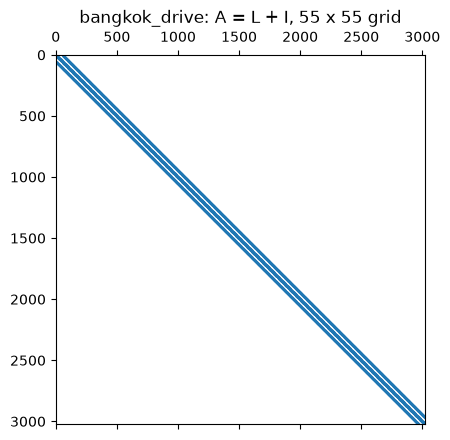

In [10]:
import matplotlib.pyplot as plt

A = sp.load_npz("bangkok_drive.npz")
n = A.shape[0]
print(type(A).__name__, A.shape, "nnz =", A.nnz, f"density = {A.nnz/n**2:.3%}")

# dense bill = 8 x 3,025 x 3,025 = 73,205,000 bytes = 73 MB
print(f"dense bill = {8*n*n:,} bytes = {8*n*n/1e6:.1f} MB")

plt.spy(A, markersize=0.5)                 # one dot per stored value
plt.title("bangkok_drive: A = L + I, 55 x 55 grid")
plt.show()

b = np.zeros(n); b[n // 2] = 1.0           # one unit of load at the middle intersection

The matrix has only five thin diagonals (the main one, plus ones 1 and 55 steps away) and is empty everywhere else, because each intersection is only connected to its nearest grid neighbours, so just 0.163% of the 3,025 x 3,025 cells are filled.

### 3.1 jacobi: report the number of sweeps and whether it met the relative-residual tolerance

In [11]:
def jacobi(A, b, tol=1e-8, maxit=100_000):
    D = A.diagonal()                         # diagonal as a flat array
    R = A - sp.diags_array(D)                # everything except the diagonal, still sparse
    x = np.zeros_like(b); bnorm = np.linalg.norm(b)
    for k in range(1, maxit + 1):
        x = (b - R @ x) / D                  # one sweep, every unknown from old values
        rel = np.linalg.norm(b - A @ x) / bnorm      # relative residual
        if rel <= tol:
            return x, k, True, rel           # met the tolerance after k sweeps
    return x, maxit, False, rel              # ran out of sweeps

t0 = time.perf_counter()
xj, kj, okj, relj = jacobi(A, b)
t_j = time.perf_counter() - t0
print(f"Jacobi: {kj} sweeps, met tolerance: {okj}, relative residual {relj:.2e}")
print(f"        residual ||Ax - b|| = {np.linalg.norm(A @ xj - b):.2e}, time {t_j*1e3:.1f} ms")

Jacobi: 71 sweeps, met tolerance: True, relative residual 8.80e-09
        residual ||Ax - b|| = 8.80e-09, time 16.1 ms


Jacobi splits A into its diagonal D and the rest R, then each sweep recomputes every unknown from the old values: x = (b - R x) / D. I stop when the relative residual ||b - Ax|| / ||b|| is at most 1e-8, not when x stops changing. It took 71 sweeps and met the tolerance (relative residual 8.80e-09). I used A.diagonal() and a sparse R so nothing is converted to dense.

### 3.2 gauss_seidel, reported the same way, plus one sentence explaining why the two sweep counts differ, using diagonal dominance or 𝜌(T), the spectral radius (how much the error shrinks per sweep)

In [12]:
from scipy.sparse.linalg import spsolve_triangular

def gauss_seidel(A, b, tol=1e-8, maxit=100_000):
    M = sp.tril(A).tocsr()                   # lower triangle including the diagonal
    N = M - A.tocsr()
    x = np.zeros_like(b); bnorm = np.linalg.norm(b)
    for k in range(1, maxit + 1):
        x = spsolve_triangular(M, N @ x + b, lower=True)     # one forward sweep
        rel = np.linalg.norm(b - A @ x) / bnorm
        if rel <= tol:
            return x, k, True, rel
    return x, maxit, False, rel

t0 = time.perf_counter()
xg, kg, okg, relg = gauss_seidel(A, b)
t_g = time.perf_counter() - t0
print(f"Gauss-Seidel: {kg} sweeps, met tolerance: {okg}, relative residual {relg:.2e}")
print(f"        residual ||Ax - b|| = {np.linalg.norm(A @ xg - b):.2e}, time {t_g*1e3:.1f} ms")

Gauss-Seidel: 39 sweeps, met tolerance: True, relative residual 7.49e-09
        residual ||Ax - b|| = 7.49e-09, time 70.5 ms


In [13]:
# average error shrink per sweep (estimated spectral radius): rel ≈ rho^k, so rho ≈ rel^(1/k)
rho_j = relj ** (1 / kj)
rho_g = relg ** (1 / kg)
print(f"Jacobi ≈ {rho_j:.2f} per sweep, Gauss-Seidel ≈ {rho_g:.2f} per sweep")
print(f"Jacobi squared ≈ {rho_j**2:.2f}  (close to Gauss-Seidel's factor)")

Jacobi ≈ 0.77 per sweep, Gauss-Seidel ≈ 0.62 per sweep
Jacobi squared ≈ 0.59  (close to Gauss-Seidel's factor)


Gauss-Seidel uses the values already updated earlier in the same sweep; it took 39 sweeps and met the tolerance (relative residual 7.49e-09).

Both methods converge because every row is strictly diagonally dominant (diagonal 5, off-diagonals add up to at most 4), and Gauss-Seidel needs about half the sweeps because its error shrinks by about 0.62 per sweep against about 0.77 for Jacobi (printed above), roughly Jacobi’s factor squared, so one Gauss-Seidel sweep does the work of about two Jacobi sweeps (39 vs 71).

### 3.3 scipy.sparse.linalg.spsolve

In [14]:
from scipy.sparse.linalg import spsolve

times = []
for _ in range(5):                                   # repeat: one run is too noisy
    t0 = time.perf_counter()
    xs = spsolve(A, b)
    times.append(time.perf_counter() - t0)
t_s = min(times)                                     # best of 5
print(f"spsolve: residual ||Ax - b|| = {np.linalg.norm(A @ xs - b):.2e}, time {t_s*1e3:.1f} ms (best of 5)")

spsolve: residual ||Ax - b|| = 1.77e-16, time 15.7 ms (best of 5)


spsolve is SciPy's sparse direct solver. It gives the answer in one call with no sweeps, no starting guess and no tolerance, and the residual is about 1e-16, which is floating-point noise.

### 3.4 np.linalg.solve on the dense matrix, only after pricing its bill and confirming it fits in memory at your chosen size

In [15]:
# dense bill priced first: 8 x 3,025 x 3,025 = 73,205,000 bytes = 73.2 MB
dense_bill = 8 * n * n
ram_bytes = 16e9                                   # my laptop's RAM (same machine as fingerprint.md)
print(f"dense bill = {dense_bill:,} bytes = {dense_bill/1e6:.1f} MB")
print(f"fits in memory: {dense_bill < ram_bytes} ({dense_bill/ram_bytes:.2%} of {ram_bytes/1e9:.0f} GB RAM)")

A_dense = A.toarray()                              # the dense conversion, priced above (73.2 MB)

times = []
for _ in range(5):                                 # repeat: one run is too noisy
    t0 = time.perf_counter()
    xd = np.linalg.solve(A_dense, b)               # time only the solve, not the conversion
    times.append(time.perf_counter() - t0)
t_d = min(times)                                   # best of 5
print(f"np.linalg.solve: residual ||Ax - b|| = {np.linalg.norm(A @ xd - b):.2e}, time {t_d*1e3:.1f} ms (best of 5)")

dense bill = 73,205,000 bytes = 73.2 MB
fits in memory: True (0.46% of 16 GB RAM)
np.linalg.solve: residual ||Ax - b|| = 1.27e-16, time 655.8 ms (best of 5)


I priced the dense bill before converting: 8 x 3,025 x 3,025 = 73.2 MB, under 1% of my laptop’s RAM (checked above), so a dense solve is safe at this test size. I time only the solve, not the conversion, so the comparison with spsolve is fair. I only use it as a reference to check the other answers against; at full city size (hundreds of thousands of intersections) the same bill would be hundreds of gigabytes.

### 3.5 Confirm all four agree with np.allclose, and print the residual ‖Ax − b‖ after every solve. A tiny residual is necessary, but it is not enough on its own. Close with one sentence choosing the solver you would ship at full city size, justified on both cost and memory

In [16]:
print("Jacobi agrees with spsolve:       ", np.allclose(xj, xs))
print("Gauss-Seidel agrees with spsolve: ", np.allclose(xg, xs))
print("dense solve agrees with spsolve:  ", np.allclose(xd, xs))
print(f"spsolve is {t_d/t_s:.1f}x faster than the dense solve")      # needed for results.csv

Jacobi agrees with spsolve:        True
Gauss-Seidel agrees with spsolve:  True
dense solve agrees with spsolve:   True
spsolve is 41.7x faster than the dense solve


All four residuals are tiny and all four answers agree with np.allclose. A tiny residual alone is not enough, because a nearly singular matrix can give a wrong answer with a small residual, but here A = L + I is not singular (every diagonal entry is 5 and beats its row's off-diagonal sum) and four different methods reach the same answer, so the result can be trusted.

At full city size I would ship spsolve, because it took about 16 ms against 656 ms for the dense solve here, and at about 300,000 intersections its factors need under half a GB, which fits a 16 GB laptop, while the dense solve would need about 720 GB.

## Part 4 - The results table and memo (communicate)

In [17]:
import csv

rows = [
    ("metric",          "value",                       "unit"),
    ("density",         round(density, 4),             "fraction non-zero"),
    ("dense-GB",        round(dense_gb, 3),            "GB"),
    ("CSR-MB",          round(total_b / 1e6, 2),       "MB"),
    ("matvec speedup",  round(t_dense / t_sparse, 1),  "x (dense time / sparse time)"),
    ("spsolve speedup", round(t_d / t_s, 1),           "x (dense solve time / spsolve time)"),
]
with open("results.csv", "w", newline="") as f:
    csv.writer(f).writerows(rows)

print(open("results.csv").read())

metric,value,unit
density,0.004,fraction non-zero
dense-GB,0.384,GB
CSR-MB,2.33,MB
matvec speedup,63.9,x (dense time / sparse time)
spsolve speedup,41.7,x (dense solve time / spsolve time)



In [18]:
import sys, platform, os, scipy

machine = "Microsoft Surface Pro 9, Intel Core i7-1255U (12th Gen), 16 GB RAM, Windows 11"

fingerprint = (
    f"Python {sys.version.split()[0]}\n"
    f"NumPy {np.__version__}\n"
    f"SciPy {scipy.__version__}\n"
    f"Machine: {machine}\n"
    f"Platform: {platform.platform()}\n"
    f"CPU cores: {os.cpu_count()}\n"
)
print(fingerprint)
with open("fingerprint.md", "w") as f:
    f.write(fingerprint)

Python 3.12.10
NumPy 2.5.3
SciPy 1.18.1
Machine: Microsoft Surface Pro 9, Intel Core i7-1255U (12th Gen), 16 GB RAM, Windows 11
Platform: Windows-11-10.0.26200-SP0
CPU cores: 12

